# CIFAR-10: exploring, clustering and classifying
Loading the data and picking the training, validation and test samples used in every part.

In [1]:
import platform
import random
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
import torchvision
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support, silhouette_score)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from torch import nn
from torchvision import datasets
from torchvision.models import ResNet18_Weights, resnet18
from torchvision.transforms import v2

In [2]:
SEED = 32

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
# numpy's random numbers can change between versions, so print them
print(f"python {platform.python_version()}, numpy {np.__version__}, "
      f"torch {torch.__version__}, torchvision {torchvision.__version__}")
print(f"seed {SEED}, device {device}")

python 3.13.3, numpy 2.5.5, torch 2.15.0, torchvision 0.29.2
seed 32, device mps


In [3]:
train_set = datasets.CIFAR10("data", train=True, download=True)
test_set = datasets.CIFAR10("data", train=False, download=True)

train_images, train_labels = train_set.data, np.array(train_set.targets)
test_images, test_labels = test_set.data, np.array(test_set.targets)
classes = train_set.classes
print(train_images.shape, test_images.shape)

(50000, 32, 32, 3) (10000, 32, 32, 3)


In [4]:
sns.set_theme(style="white", context="paper")
# font sizes set once so all figures match in the report
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight",
                     "image.interpolation": "nearest", "font.size": 6.5,
                     "axes.titlesize": 7, "axes.labelsize": 6.5, "xtick.labelsize": 6,
                     "ytick.labelsize": 6, "legend.fontsize": 6, "figure.titlesize": 7.5,
                     "axes.titlepad": 2})
TEXT_WIDTH = 6.85  # page width in inches
class_colours = dict(zip(classes, sns.color_palette("tab10", len(classes))))
short_names = ["plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

## Samples
Each class is shuffled once with the seed. 500 training and 50 validation images per class come from the training set, and 50 test images per class from the test set.

In [5]:
rng = np.random.default_rng(SEED)

def sample_per_class(labels, sizes):
    # shuffle each class once and slice it, so the samples never overlap
    samples = [[] for _ in sizes]
    for c in range(len(classes)):
        idx = rng.permutation(np.flatnonzero(labels == c))
        start = 0
        for sample, n in zip(samples, sizes):
            sample.append(idx[start:start + n])
            start += n
    return [np.sort(np.concatenate(s)) for s in samples]

train_idx, val_idx = sample_per_class(train_labels, [500, 50])
(test_idx,) = sample_per_class(test_labels, [50])

for name, idx, labels in [("train", train_idx, train_labels),
                          ("val", val_idx, train_labels),
                          ("test", test_idx, test_labels)]:
    print(name, len(idx), np.bincount(labels[idx]))
print("train and val overlap:", len(np.intersect1d(train_idx, val_idx)))

train 5000 [500 500 500 500 500 500 500 500 500 500]
val 500 [50 50 50 50 50 50 50 50 50 50]
test 500 [50 50 50 50 50 50 50 50 50 50]
train and val overlap: 0


## Part A

## A1
How many images each set has, and the average and spread of each colour. Then one example image per class.

In [6]:
set_labels = {"train full": train_labels, "test full": test_labels,
              "train sample": train_labels[train_idx], "val sample": train_labels[val_idx],
              "test sample": test_labels[test_idx]}
set_counts = pd.DataFrame({"images": [len(y) for y in set_labels.values()],
                           "min per class": [np.bincount(y).min() for y in set_labels.values()],
                           "max per class": [np.bincount(y).max() for y in set_labels.values()]},
                          index=set_labels)
print(set_counts)

              images  min per class  max per class
train full     50000           5000           5000
test full      10000           1000           1000
train sample    5000            500            500
val sample       500             50             50
test sample      500             50             50


In [7]:
def channel_stats(images):
    pixels = images.reshape(-1, 3)
    # one colour at a time to save memory
    std = np.array([pixels[:, ch].std() for ch in range(3)])
    return pixels.mean(axis=0) / 255, std / 255

# worked out again in A3 after cleaning
channel_mean, channel_std = channel_stats(train_images[train_idx])
full_mean, full_std = channel_stats(train_images)

print(f"pixels {train_images.dtype}, range {train_images.min()} to {train_images.max()}")
print(pd.DataFrame({"sample mean": channel_mean, "sample std": channel_std,
                    "full mean": full_mean, "full std": full_std},
                   index=["red", "green", "blue"]).round(3))
print(f"largest sample-to-full gap {max(np.abs(channel_mean - full_mean).max(), np.abs(channel_std - full_std).max()):.3f}")

pixels uint8, range 0 to 255
       sample mean  sample std  full mean  full std
red          0.491       0.247      0.491     0.247
green        0.482       0.243      0.482     0.243
blue         0.445       0.261      0.447     0.262
largest sample-to-full gap 0.002


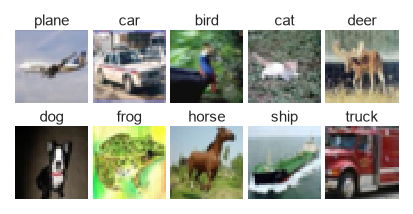

In [8]:
first_per_class = [train_idx[train_labels[train_idx] == c][0] for c in range(len(classes))]

fig, axes = plt.subplots(2, 5, figsize=(3.3, 1.5), gridspec_kw={"wspace": 0.06, "hspace": 0.25})
for ax, i, name in zip(axes.flat, first_per_class, short_names):
    ax.imshow(train_images[i])
    ax.set_title(name)
    ax.axis("off")
fig.savefig("figures/a1_examples.png")
plt.show()

## A2
Finding near-copies by comparing each image's closest and second-closest match. Then scoring image quality and checking which classes look alike.

In [9]:
def flatten(images):
    return images.reshape(len(images), -1).astype(np.float32) / 255

pca = PCA(n_components=0.95, random_state=SEED).fit(flatten(train_images[train_idx]))
all_images = np.concatenate([train_images, test_images])
# 10,000 images at a time to save memory
all_z = np.concatenate([pca.transform(flatten(all_images[i:i + 10000]))
                        for i in range(0, len(all_images), 10000)])
print(f"{pca.n_components_} components keep {pca.explained_variance_ratio_.sum():.3f} of the variance; "
      f"{len(all_images)} images projected")

nn_dist, nn_idx = NearestNeighbors(n_neighbors=3).fit(all_z).kneighbors(all_z)
nearest = nn_dist[:, 1]
# a copy is much closer than the next-nearest image, even if shifted
nearest_ratio = nearest / nn_dist[:, 2]
print(f"smallest nearest distance {nearest.min():.2f}")

clear_copy, clear_non_copy = nearest_ratio < 0.5, nearest_ratio >= 0.9
print(f"pairs with ratio < 0.5 reach nearest distance {nearest[clear_copy].max():.2f}")
print("images with ratio >= 0.9 closer than that:",
      (clear_non_copy & (nearest < nearest[clear_copy].max())).sum())

206 components keep 0.950 of the variance; 60000 images projected


smallest nearest distance 1.54
pairs with ratio < 0.5 reach nearest distance 5.79
images with ratio >= 0.9 closer than that: 4628


In [10]:
COUNT_CUT = 0.8  # Lowe (2004)
# an extra swap costs nothing, so swaps use a looser cut
REPLACE_CUT = 0.85
n_train = len(train_images)

def pairs_below(cut):
    below = np.flatnonzero(nearest_ratio < cut)
    return np.unique(np.sort(np.column_stack([below, nn_idx[below, 1]]), axis=1), axis=0)

def sample_pair_counts(train_members, pairs):
    role = np.full(len(all_images), "", dtype=object)
    role[train_members], role[val_idx], role[n_train + test_idx] = "train", "val", "test"
    # an empty string means the image is in no sample
    counts = Counter(tuple(sorted(r)) for r in role[pairs] if r[0] and r[1])
    return ", ".join(f"{a}-{b} {counts[(a, b)]}"
                     for a, b in [("train", "val"), ("test", "train"), ("test", "val"), ("train", "train")])

for cut in [COUNT_CUT, REPLACE_CUT]:
    pairs = pairs_below(cut)
    test_ends = (pairs >= n_train).sum(axis=1)
    print(f"ratio < {cut}: full sets within train {(test_ends == 0).sum()}, train-test {(test_ends == 1).sum()}, "
          f"within test {(test_ends == 2).sum()}; samples {sample_pair_counts(train_idx, pairs)}")

near_dup_pairs = pairs_below(REPLACE_CUT)

ratio < 0.8: full sets within train 1028, train-test 423, within test 31; samples train-val 5, test-train 0, test-val 0, train-train 5
ratio < 0.85: full sets within train 1475, train-test 613, within test 40; samples train-val 7, test-train 1, test-val 0, train-train 5


In [11]:
def quality_table(images):
    grey = images @ np.array([0.299, 0.587, 0.114]) / 255
    laplacian = (grey[:, :-2, 1:-1] + grey[:, 2:, 1:-1] + grey[:, 1:-1, :-2]
                 + grey[:, 1:-1, 2:] - 4 * grey[:, 1:-1, 1:-1])
    # log because a few images have very large values
    return pd.DataFrame({"brightness": grey.mean(axis=(1, 2)), "contrast": grey.std(axis=(1, 2)),
                         "log sharpness": np.log(laplacian.var(axis=(1, 2)))})

def modified_z(x):
    return 0.6745 * (x - x.median()) / (x - x.median()).abs().median()

quality = quality_table(train_images[train_idx])
quality_z = quality.apply(modified_z)
quality_flags = quality_z.abs() > 3.5
corrupt = quality["contrast"] == 0
print(pd.DataFrame({"low": (quality_z < -3.5).sum(), "high": (quality_z > 3.5).sum()}).T)
print("flagged by any check:", quality_flags.any(axis=1).sum(), "of", len(quality))
print("constant images (corrupt):", corrupt.sum())

      brightness  contrast  log sharpness
low            2         0             11
high          10         1              0
flagged by any check: 24 of 5000
constant images (corrupt): 0


In [12]:
train_z = all_z[train_idx]
sample_y = train_labels[train_idx]
_, knn_idx = NearestNeighbors(n_neighbors=11).fit(train_z).kneighbors(train_z)
neighbour_y = sample_y[knn_idx[:, 1:]]
other_share = (neighbour_y != sample_y[:, None]).mean(axis=1)

neighbour_matrix = pd.crosstab(np.array(classes)[np.repeat(sample_y, 10)],
                               np.array(classes)[neighbour_y.ravel()],
                               rownames=["image"], colnames=["neighbour"], normalize="index")
neighbour_matrix = neighbour_matrix.loc[classes, classes]
neighbour_share = pd.Series(neighbour_y.ravel()).value_counts(normalize=True).sort_index().set_axis(classes)
print(f"mean share of neighbours from another class {other_share.mean():.3f} (chance 0.9)")
print("images with all 10 neighbours from other classes:", (other_share == 1).sum())
print("share of all neighbours by class:", neighbour_share.round(3).to_dict())
off_diagonal = neighbour_matrix.where(~np.eye(len(classes), dtype=bool)).stack()
print(off_diagonal.sort_values(ascending=False).head(6).round(3).to_string())

# lift corrects for classes like deer that are everyone's neighbour
lift = neighbour_matrix / neighbour_share
mutual_lift = pd.Series({f"{a} and {b}": min(lift.loc[a, b], lift.loc[b, a])
                         for i, a in enumerate(classes) for b in classes[i + 1:]})
print("strongest mutual pairs by lift (smaller of the two directions):")
print(mutual_lift.sort_values(ascending=False).head(5).round(2).to_string())
for a, b in [("airplane", "ship"), ("cat", "dog"), ("bird", "deer")]:
    print(f"{a} to {b} {neighbour_matrix.loc[a, b]:.3f} (lift {lift.loc[a, b]:.2f}), "
          f"{b} to {a} {neighbour_matrix.loc[b, a]:.3f} (lift {lift.loc[b, a]:.2f})")
print(f"frog to deer lift {lift.loc['frog', 'deer']:.2f}")

mean share of neighbours from another class 0.771 (chance 0.9)
images with all 10 neighbours from other classes: 1169
share of all neighbours by class: {'airplane': 0.129, 'automobile': 0.024, 'bird': 0.163, 'cat': 0.061, 'deer': 0.193, 'dog': 0.072, 'frog': 0.134, 'horse': 0.051, 'ship': 0.133, 'truck': 0.039}
image     neighbour
frog      deer         0.270
bird      deer         0.237
horse     deer         0.224
airplane  ship         0.220
deer      bird         0.219
truck     ship         0.218
strongest mutual pairs by lift (smaller of the two directions):
automobile and truck    1.75
cat and dog             1.66
airplane and ship       1.59
bird and deer           1.23
automobile and ship     1.18
airplane to ship 0.220 (lift 1.65), ship to airplane 0.206 (lift 1.59)
cat to dog 0.120 (lift 1.66), dog to cat 0.113 (lift 1.86)
bird to deer 0.237 (lift 1.23), deer to bird 0.219 (lift 1.34)
frog to deer lift 1.40


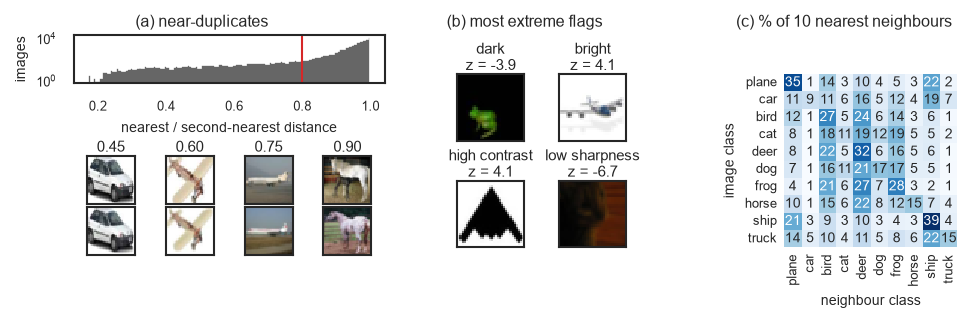

shown pairs: ratio [0.45 0.6  0.75 0.9 ] distance [ 5.79  5.03  3.93 10.08]


In [13]:
fig = plt.figure(figsize=(TEXT_WIDTH, 1.65))
panel_a, panel_b, panel_c = fig.subfigures(1, 3, width_ratios=[1.15, 0.72, 1.13], wspace=0.02)

hist_part, pair_part = panel_a.subfigures(2, 1, height_ratios=[1.05, 1])
hist_ax = hist_part.subplots()
hist_part.subplots_adjust(left=0.17, right=0.97, bottom=0.42, top=0.8)
hist_ax.hist(nearest_ratio, bins=100, color="0.4", histtype="stepfilled")
hist_ax.axvline(COUNT_CUT, color="tab:red", lw=1)
hist_ax.set(yscale="log", ylabel="images", xlabel="nearest / second-nearest distance")
farthest_copy = np.flatnonzero(clear_copy)[nearest[clear_copy].argmax()]
shown = [farthest_copy] + [np.abs(nearest_ratio - r).argmin() for r in [0.6, 0.75, 0.9]]
pair_axes = pair_part.subplots(2, 4, gridspec_kw={"wspace": 0.06, "hspace": 0.06})
pair_part.subplots_adjust(left=0.17, right=0.97, bottom=0.02, top=0.84)
for col, k in enumerate(shown):
    pair_axes[0, col].imshow(all_images[k])
    pair_axes[1, col].imshow(all_images[nn_idx[k, 1]])
    pair_axes[0, col].set_title(f"{nearest_ratio[k]:.2f}")
for ax in pair_axes.flat:
    ax.set(xticks=[], yticks=[])
panel_a.suptitle("(a) near-duplicates")

flagged_examples = [("dark", "brightness", quality_z["brightness"].idxmin()),
                    ("bright", "brightness", quality_z["brightness"].idxmax()),
                    ("high contrast", "contrast", quality_z["contrast"].idxmax()),
                    ("low sharpness", "log sharpness", quality_z["log sharpness"].idxmin())]
quality_axes = panel_b.subplots(2, 2, gridspec_kw={"wspace": 0.1, "hspace": 0.6})
panel_b.subplots_adjust(top=0.74, bottom=0.04)
for ax, (name, metric, k) in zip(quality_axes.flat, flagged_examples):
    ax.imshow(train_images[train_idx[k]])
    ax.set_title(f"{name}\nz = {quality_z.loc[k, metric]:.1f}")
    ax.set(xticks=[], yticks=[])
panel_b.suptitle("(b) most extreme flags")

heat_ax = panel_c.subplots()
sns.heatmap(neighbour_matrix * 100, ax=heat_ax, cmap="Blues", annot=True, fmt=".0f",
            cbar=False, square=True, xticklabels=short_names, yticklabels=short_names)
heat_ax.set(xlabel="neighbour class", ylabel="image class")
heat_ax.tick_params(length=0)
panel_c.suptitle("(c) % of 10 nearest neighbours")

fig.savefig("figures/a2_quality.png")
plt.show()
print("shown pairs: ratio", nearest_ratio[shown].round(2), "distance", nearest[shown].round(2))

## A3
Swapping out training images that have a copy in validation or test. Then normalising, and setting up augmentation for Part C.

In [14]:
# separate random stream so the original samples stay the same
replace_rng = np.random.default_rng(SEED + 1)
eval_members = np.concatenate([val_idx, n_train + test_idx])
leak_partners = set(near_dup_pairs[np.isin(near_dup_pairs, eval_members).any(axis=1)].ravel())
leaked = sorted(leak_partners & set(train_idx))

clean_train_idx = train_idx.copy()
taken = set(train_idx) | set(val_idx)
for i in leaked:
    same_class = np.flatnonzero(train_labels == train_labels[i])
    candidates = [j for j in same_class if j not in taken and j not in leak_partners]
    swap = replace_rng.choice(candidates)
    clean_train_idx[clean_train_idx == i] = swap
    taken.add(swap)
clean_train_idx = np.sort(clean_train_idx)

print("training images replaced:", len(leaked), [classes[train_labels[i]] for i in leaked],
      "replacement seed", SEED + 1)
print(f"after the swaps, pairs below {REPLACE_CUT}: {sample_pair_counts(clean_train_idx, near_dup_pairs)}")
clean_flags = (quality_table(train_images[clean_train_idx]).apply(modified_z).abs() > 3.5).any(axis=1)
print("removed as corrupt:", corrupt.sum(), "; flagged in the cleaned sample:", clean_flags.sum())
print("cleaned train", len(clean_train_idx), np.bincount(train_labels[clean_train_idx]),
      "overlap with val", len(np.intersect1d(clean_train_idx, val_idx)))

training images replaced: 8 ['bird', 'frog', 'airplane', 'deer', 'airplane', 'airplane', 'frog', 'bird'] replacement seed 33
after the swaps, pairs below 0.85: train-val 0, test-train 0, test-val 0, train-train 5
removed as corrupt: 0 ; flagged in the cleaned sample: 23
cleaned train 5000 [500 500 500 500 500 500 500 500 500 500] overlap with val 0


In [15]:
channel_mean, channel_std = channel_stats(train_images[clean_train_idx])
print(pd.DataFrame({"mean": channel_mean, "std": channel_std},
                   index=["red", "green", "blue"]).round(3))

def to_tensor(images):
    x = torch.tensor(images, dtype=torch.float32).permute(0, 3, 1, 2) / 255
    # use the training averages for every set
    mean = torch.tensor(channel_mean, dtype=torch.float32).view(1, 3, 1, 1)
    std = torch.tensor(channel_std, dtype=torch.float32).view(1, 3, 1, 1)
    return (x - mean) / std

train_x, train_y = to_tensor(train_images[clean_train_idx]), torch.tensor(train_labels[clean_train_idx])
val_x, val_y = to_tensor(train_images[val_idx]), torch.tensor(train_labels[val_idx])
print("train mean", train_x.mean((0, 2, 3)).numpy().round(3), "std", train_x.std((0, 2, 3)).numpy().round(3))
print("val mean", val_x.mean((0, 2, 3)).numpy().round(3), "std", val_x.std((0, 2, 3)).numpy().round(3))

# padding after normalising fills the border with the average colour
augment = v2.Compose([v2.RandomCrop(32, padding=4), v2.RandomHorizontalFlip()])

        mean    std
red    0.491  0.247
green  0.482  0.243
blue   0.445  0.261


train mean [0. 0. 0.] std [1. 1. 1.]
val mean [0.006 0.02  0.043] std [1.026 1.031 1.026]


## Part B

## B1
Two ways to describe each image: its normalised pixels, and 512 numbers from a ResNet-18 trained on ImageNet. Each is scaled and squashed with PCA to keep 90% of the variance.

In [16]:
pixel_features = train_x.reshape(len(train_x), -1).numpy()

resnet = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
resnet.fc = nn.Identity()
resnet.eval().to(device)
# ResNet expects ImageNet averages and 224 x 224 images
imagenet_mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
imagenet_std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
raw_train = torch.tensor(train_images[clean_train_idx], dtype=torch.float32).permute(0, 3, 1, 2) / 255
batches = []
with torch.no_grad():
    for i in range(0, len(raw_train), 250):
        xb = (raw_train[i:i + 250] - imagenet_mean) / imagenet_std
        xb = F.interpolate(xb, size=224, mode="bilinear", align_corners=False)
        batches.append(resnet(xb.to(device)).cpu())
embeddings = torch.cat(batches).numpy()
print("pixel features", pixel_features.shape, "embeddings", embeddings.shape)

pixel features (5000, 3072) embeddings (5000, 512)


In [17]:
feature_sets = {"pixels": pixel_features, "embeddings": embeddings}
pca_features, pca_models = {}, {}
for name, features in feature_sets.items():
    # scale first so no single number dominates
    standardised = StandardScaler().fit_transform(features)
    pca_models[name] = PCA(n_components=0.90, random_state=SEED).fit(standardised)
    pca_features[name] = pca_models[name].transform(standardised)
    ratio = pca_models[name].explained_variance_ratio_
    print(f"{name}: {pca_models[name].n_components_} components for {ratio.sum():.3f} of variance, "
          f"PC1 {ratio[0]:.3f}, PC2 {ratio[1]:.3f}")

pixels: 100 components for 0.900 of variance, PC1 0.265, PC2 0.113


embeddings: 193 components for 0.900 of variance, PC1 0.077, PC2 0.041


pixels: 100 components for 90%, 210 for 95%
embeddings: 193 components for 90%, 274 for 95%
correlation of pixel PC1 with mean brightness: 0.988


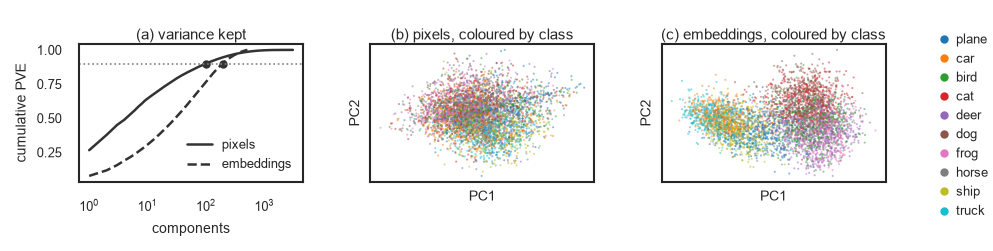

In [18]:
pve_curves = {name: np.cumsum(PCA(random_state=SEED).fit(StandardScaler().fit_transform(f))
                              .explained_variance_ratio_) for name, f in feature_sets.items()}
cluster_y = train_labels[clean_train_idx]
for name, curve in pve_curves.items():
    print(f"{name}: {np.searchsorted(curve, 0.90) + 1} components for 90%, {np.searchsorted(curve, 0.95) + 1} for 95%")
print("correlation of pixel PC1 with mean brightness:",
      np.corrcoef(pca_features["pixels"][:, 0], pixel_features.mean(axis=1))[0, 1].round(3))

fig, axes = plt.subplots(1, 3, figsize=(TEXT_WIDTH, 1.2))
for name, style in [("pixels", "-"), ("embeddings", "--")]:
    axes[0].plot(np.arange(1, len(pve_curves[name]) + 1), pve_curves[name], style, color="0.2", label=name)
    axes[0].plot(pca_models[name].n_components_, 0.9, "o", color="0.2", ms=3)
axes[0].axhline(0.9, color="0.5", lw=0.8, ls=":")
axes[0].set(xscale="log", xlabel="components", ylabel="cumulative PVE", title="(a) variance kept")
axes[0].legend(frameon=False, loc="lower right")
for ax, name, letter in [(axes[1], "pixels", "b"), (axes[2], "embeddings", "c")]:
    pcs = pca_features[name][:, :2]
    ax.scatter(pcs[:, 0], pcs[:, 1], c=[class_colours[classes[c]] for c in cluster_y], s=1, alpha=0.5, lw=0)
    ax.set(xticks=[], yticks=[], xlabel="PC1", ylabel="PC2", title=f"({letter}) {name}, coloured by class")
handles = [plt.Line2D([], [], marker="o", ls="", ms=3, color=class_colours[c]) for c in classes]
fig.legend(handles, short_names, loc="center right", frameon=False, handletextpad=0, borderaxespad=0)
fig.subplots_adjust(right=0.91, wspace=0.3)
fig.savefig("figures/b1_pca.png")
plt.show()

## B2
Grouping the images with k-means and Ward, without labels. The silhouette and the elbow are used to choose how many groups.

In [19]:
sweep_rows, cluster_labels = [], {}
for name, z in pca_features.items():
    for k in range(2, 21):
        kmeans = KMeans(k, n_init=10, random_state=SEED).fit(z)
        ward = AgglomerativeClustering(k, linkage="ward").fit(z)
        for method, labels in [("k-means", kmeans.labels_), ("Ward", ward.labels_)]:
            cluster_labels[name, method, k] = labels
            sweep_rows.append({"features": name, "method": method, "k": k,
                               "silhouette": silhouette_score(z, labels),
                               "inertia": kmeans.inertia_ if method == "k-means" else np.nan})
sweep = pd.DataFrame(sweep_rows)

for (name, method), group in sweep.groupby(["features", "method"]):
    top = group.nlargest(2, "silhouette")
    print(f"{name}, {method}: best k {top.k.iloc[0]} ({top.silhouette.iloc[0]:.3f}), "
          f"next k {top.k.iloc[1]} ({top.silhouette.iloc[1]:.3f})")
print("largest silhouette anywhere", sweep.silhouette.max().round(3))

# the elbow is the point furthest from the line joining the two ends
elbow = {}
for name in feature_sets:
    inertia = sweep.query("features == @name and method == 'k-means'").set_index("k").inertia
    scaled = (inertia - inertia.iloc[-1]) / (inertia.iloc[0] - inertia.iloc[-1])
    chord = (scaled.index - 2) / 18
    gap = (1 - chord - scaled).abs() / np.sqrt(2)
    elbow[name] = gap.idxmax()
    print(f"{name} elbow k {gap.idxmax()}, chord gap {gap.max():.3f}, "
          f"k with gap within 0.01 of it: {list(gap.index[gap > gap.max() - 0.01])}")

embeddings, Ward: best k 2 (0.059), next k 3 (0.042)
embeddings, k-means: best k 2 (0.064), next k 4 (0.051)
pixels, Ward: best k 2 (0.122), next k 3 (0.084)
pixels, k-means: best k 2 (0.163), next k 3 (0.114)
largest silhouette anywhere 0.163
pixels elbow k 7, chord gap 0.273, k with gap within 0.01 of it: [6, 7, 8]
embeddings elbow k 8, chord gap 0.219, k with gap within 0.01 of it: [6, 7, 8, 9, 10]


## B3
Now the labels are used to see how well the groups match the real classes, at k = 2 and k = 10.

In [20]:
def purity(labels):
    return sum(np.bincount(cluster_y[labels == c]).max() for c in np.unique(labels)) / len(cluster_y)

scores = sweep.query("k in [2, 10]").copy()
scores["purity"] = [purity(cluster_labels[r.features, r.method, r.k]) for r in scores.itertuples()]
scores["ARI"] = [adjusted_rand_score(cluster_y, cluster_labels[r.features, r.method, r.k])
                 for r in scores.itertuples()]
print(scores[["features", "method", "k", "silhouette", "purity", "ARI"]].round(3).to_string(index=False))

is_vehicle = np.isin(cluster_y, [classes.index(c) for c in ["airplane", "automobile", "ship", "truck"]])
for name in feature_sets:
    split = cluster_labels[name, "k-means", 2]
    agreement = max((split == is_vehicle).mean(), (split != is_vehicle).mean())
    print(f"{name} k-means k = 2 against animal or vehicle: {agreement:.3f} agreement")

cluster_tables = {}
for name in feature_sets:
    table = pd.crosstab(cluster_labels[name, "k-means", 10], cluster_y).set_axis(classes, axis=1)
    cluster_tables[name] = table.loc[table.idxmax(axis=1).map(classes.index).sort_values().index]
    cluster_mean_brightness = pd.Series(pixel_features.mean(axis=1)).groupby(cluster_labels[name, "k-means", 10]).mean()
    print(f"{name} k-means, k = 10 (rows are clusters):")
    print(cluster_tables[name].assign(brightness=cluster_mean_brightness.round(2)).to_string())
emb_table = cluster_tables["embeddings"]

  features  method  k  silhouette  purity   ARI
    pixels k-means  2       0.163   0.155 0.022
    pixels    Ward  2       0.122   0.140 0.010
    pixels k-means 10       0.056   0.224 0.044
    pixels    Ward 10       0.023   0.216 0.038
embeddings k-means  2       0.064   0.198 0.151
embeddings    Ward  2       0.059   0.196 0.150
embeddings k-means 10       0.028   0.682 0.461
embeddings    Ward 10       0.006   0.577 0.357
pixels k-means k = 2 against animal or vehicle: 0.632 agreement
embeddings k-means k = 2 against animal or vehicle: 0.951 agreement
pixels k-means, k = 10 (rows are clusters):
       airplane  automobile  bird  cat  deer  dog  frog  horse  ship  truck  brightness
row_0                                                                                  
5            99          21    54   27    17   23    18      9    26     18        1.03
3            53         105    43   34    35   77    35     47   103     51       -0.19
7            21          35   103   73  

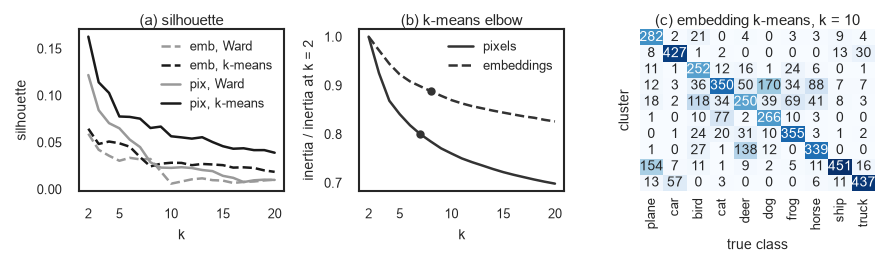

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(TEXT_WIDTH, 1.4), gridspec_kw={"width_ratios": [1, 1, 1.15]})
for (name, method), group in sweep.groupby(["features", "method"]):
    axes[0].plot(group.k, group.silhouette, "-" if name == "pixels" else "--",
                 color="0.1" if method == "k-means" else "0.6", label=f"{name[:3]}, {method}")
axes[0].set(xlabel="k", ylabel="silhouette", title="(a) silhouette", xticks=[2, 5, 10, 15, 20])
axes[0].legend(frameon=False, loc="upper right", handlelength=1.5)
for name, style in [("pixels", "-"), ("embeddings", "--")]:
    inertia = sweep.query("features == @name and method == 'k-means'").set_index("k").inertia
    relative = inertia / inertia.iloc[0]
    axes[1].plot(relative.index, relative, style, color="0.2", label=name)
    axes[1].plot(elbow[name], relative[elbow[name]], "o", color="0.2", ms=3)
axes[1].set(xlabel="k", ylabel="inertia / inertia at k = 2", title="(b) k-means elbow", xticks=[2, 5, 10, 15, 20])
axes[1].legend(frameon=False)
sns.heatmap(emb_table, ax=axes[2], cmap="Blues", annot=True, fmt="d", cbar=False,
            xticklabels=short_names, yticklabels=False)
axes[2].set(xlabel="true class", ylabel="cluster", title="(c) embedding k-means, k = 10")
axes[2].tick_params(length=0)
fig.subplots_adjust(wspace=0.35)
fig.savefig("figures/b2_clusters.png")
plt.show()

## Part C

## C1
A small CNN built from scratch, trained for 30 epochs in every run (seed 32 unless stated). The version with the lowest validation loss is kept.

In [22]:
EPOCHS, BATCH, LEARNING_RATE = 30, 64, 1e-3


class CNN(nn.Module):
    def __init__(self, channels, convs_per_block=1, batch_norm=False, dropout=0.0):
        super().__init__()
        layers, c_in = [], 3
        for c_out in channels:
            for _ in range(convs_per_block):
                layers.append(nn.Conv2d(c_in, c_out, 3, padding=1))
                if batch_norm:
                    layers.append(nn.BatchNorm2d(c_out))
                layers.append(nn.ReLU())
                c_in = c_out
            layers.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*layers)
        side = 32 // 2 ** len(channels)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in * side * side, 128),
                                        nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


def predict(model, x):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(x[i:i + 500].to(device)).cpu() for i in range(0, len(x), 500)])


def evaluate(model, x, y):
    logits = predict(model, x)
    pred = logits.argmax(1)
    return F.cross_entropy(logits, y).item(), (pred == y).float().mean().item(), f1_score(y, pred, average="macro")


def train(make_model, seed, augmented=False):
    # seed first so the starting weights and batch order repeat
    torch.manual_seed(seed)
    model = make_model().to(device)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history, best_loss = [], float("inf")
    for epoch in range(1, EPOCHS + 1):
        start = time.time()
        model.train()
        order = torch.randperm(len(train_x))
        loss_sum = correct = 0
        for i in range(0, len(order), BATCH):
            idx = order[i:i + BATCH]
            xb = train_x[idx]
            if augmented:
                # a different crop and flip for each image, not one for the whole batch
                xb = torch.stack([augment(x) for x in xb])
            xb, yb = xb.to(device), train_y[idx].to(device)
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
            optimiser.zero_grad()
            loss.backward()
            optimiser.step()
            loss_sum += loss.item() * len(idx)
            correct += (logits.argmax(1) == yb).sum().item()
        val_loss, val_acc, val_f1 = evaluate(model, val_x, val_y)
        history.append({"epoch": epoch, "train_loss": loss_sum / len(order), "train_acc": correct / len(order),
                        "val_loss": val_loss, "val_acc": val_acc, "val_f1": val_f1,
                        "seconds": time.time() - start})
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

torch.manual_seed(SEED)
x = train_x[0]
print("two augmented copies of one image differ:", not torch.equal(augment(x), augment(x)))

two augmented copies of one image differ: True


In [23]:
for label, model in [("baseline", CNN([32, 32])), ("final architecture", CNN([32, 64, 128], 2, batch_norm=True))]:
    x = torch.zeros(1, 3, 32, 32)
    sizes = []
    for layer in model.features:
        x = layer(x)
        if isinstance(layer, (nn.Conv2d, nn.MaxPool2d)):
            sizes.append(f"{layer.__class__.__name__} {tuple(x.shape[1:])}")
    print(f"{label}: {', '.join(sizes)}; parameters {sum(p.numel() for p in model.parameters())}")
# output width W2 = (W1 - F + 2P) / S + 1
print("conv output width", (32 - 3 + 2 * 1) // 1 + 1)
print(f"every run: {EPOCHS} epochs, batch {BATCH}, Adam learning rate {LEARNING_RATE}, "
      f"seed {SEED} (baseline and final also {SEED + 1} and {SEED + 2})")

baseline: Conv2d (32, 32, 32), MaxPool2d (32, 16, 16), Conv2d (32, 16, 16), MaxPool2d (32, 8, 8); parameters 273706
final architecture: Conv2d (32, 32, 32), Conv2d (32, 32, 32), MaxPool2d (32, 16, 16), Conv2d (64, 16, 16), Conv2d (64, 16, 16), MaxPool2d (64, 8, 8), Conv2d (128, 8, 8), Conv2d (128, 8, 8), MaxPool2d (128, 4, 4); parameters 551466
conv output width 32
every run: 30 epochs, batch 64, Adam learning rate 0.001, seed 32 (baseline and final also 33 and 34)


## C2
Each improvement is tried on its own, then they are combined. The baseline and final model are run with three seeds to see how much the score moves by chance.

In [24]:
single_changes = {
    "baseline": (lambda: CNN([32, 32]), False),
    "augmentation": (lambda: CNN([32, 32]), True),
    "batch norm": (lambda: CNN([32, 32], batch_norm=True), False),
    "dropout 0.3": (lambda: CNN([32, 32], dropout=0.3), False),
    "deeper (VGG-style)": (lambda: CNN([32, 64, 128], 2), False),
}
combinations = {
    "aug + BN": (lambda: CNN([32, 32], batch_norm=True), True),
    "aug + BN + dropout": (lambda: CNN([32, 32], batch_norm=True, dropout=0.3), True),
    "aug + deeper": (lambda: CNN([32, 64, 128], 2), True),
    "aug + BN + deeper": (lambda: CNN([32, 64, 128], 2, batch_norm=True), True),
    "aug + BN + dropout + deeper": (lambda: CNN([32, 64, 128], 2, batch_norm=True, dropout=0.3), True),
}
histories, models = {}, {}

def run(name, seed, make_model, augmented):
    models[name, seed], histories[name, seed] = train(make_model, seed, augmented)
    best = histories[name, seed].loc[histories[name, seed].val_loss.idxmin()]
    print(f"{name:28s} seed {seed}: best epoch {int(best.epoch):2d}, val acc {best.val_acc:.3f}, "
          f"macro-F1 {best.val_f1:.3f}")

run_start = time.time()
for name, (make_model, augmented) in (single_changes | combinations).items():
    for seed in ([SEED, SEED + 1, SEED + 2] if name == "baseline" else [SEED]):
        run(name, seed, make_model, augmented)

# picked on seed 32; seeds 33 and 34 check it was not luck
final_name = max(combinations, key=lambda n: histories[n, SEED].loc[histories[n, SEED].val_loss.idxmin()].val_acc)
for seed in [SEED + 1, SEED + 2]:
    run(final_name, seed, *combinations[final_name])
print("final model:", final_name, "; total training time", round((time.time() - run_start) / 60, 1), "minutes")

baseline                     seed 32: best epoch  6, val acc 0.580, macro-F1 0.585


baseline                     seed 33: best epoch  6, val acc 0.528, macro-F1 0.519


baseline                     seed 34: best epoch  7, val acc 0.540, macro-F1 0.537


augmentation                 seed 32: best epoch 21, val acc 0.666, macro-F1 0.667


batch norm                   seed 32: best epoch  5, val acc 0.570, macro-F1 0.569


dropout 0.3                  seed 32: best epoch 10, val acc 0.582, macro-F1 0.574


... (4 outputs left out)

aug + BN + deeper            seed 32: best epoch 24, val acc 0.744, macro-F1 0.742


aug + BN + dropout + deeper  seed 32: best epoch 28, val acc 0.722, macro-F1 0.720


aug + BN + deeper            seed 33: best epoch 23, val acc 0.738, macro-F1 0.739


aug + BN + deeper            seed 34: best epoch 26, val acc 0.742, macro-F1 0.737
final model: aug + BN + deeper ; total training time 9.2 minutes


In [25]:
def summarise(name):
    runs = [h for (n, _), h in histories.items() if n == name]
    best = pd.DataFrame([h.loc[h.val_loss.idxmin()] for h in runs])
    return {"runs": len(runs), "val acc": best.val_acc.mean(), "acc low": best.val_acc.min(),
            "acc high": best.val_acc.max(), "macro-F1": best.val_f1.mean(), "best epoch": best.epoch.mean(),
            "s per epoch": np.mean([h.seconds.mean() for h in runs]),
            "last train acc": np.mean([h.train_acc.iloc[-1] for h in runs])}

results = pd.DataFrame({name: summarise(name) for name in single_changes | combinations}).T
print(results.round(3).to_string())
print("configurations compared on validation:", len(results))
for name in ["baseline", final_name]:
    p = results.loc[name, "val acc"]
    # 95% margin of error on 500 validation images
    print(f"{name}: 95% interval on 500 validation images +/- {1.96 * np.sqrt(p * (1 - p) / 500):.3f}")

                             runs  val acc  acc low  acc high  macro-F1  best epoch  s per epoch  last train acc
baseline                      3.0    0.549    0.528     0.580     0.547       6.333        0.581           1.000
augmentation                  1.0    0.666    0.666     0.666     0.667      21.000        0.705           0.686
batch norm                    1.0    0.570    0.570     0.570     0.569       5.000        0.904           0.923
dropout 0.3                   1.0    0.582    0.582     0.582     0.574      10.000        0.760           0.888
deeper (VGG-style)            1.0    0.556    0.556     0.556     0.554      10.000        1.543           0.992
aug + BN                      1.0    0.662    0.662     0.662     0.662      29.000        1.453           0.692
aug + BN + dropout            1.0    0.656    0.656     0.656     0.656      30.000        1.426           0.574
aug + deeper                  1.0    0.666    0.666     0.666     0.663      22.000        1.706

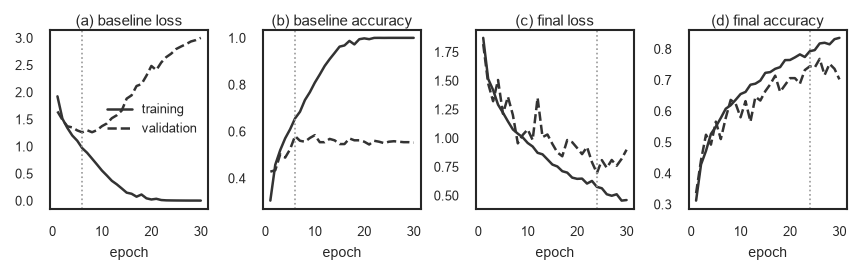

baseline: training accuracy 0.656 at epoch 6, highest 1.000 (first reached at epoch 23)
aug + BN + deeper: training accuracy 0.578 at epoch 6, highest 0.836 (first reached at epoch 30)


In [26]:
fig, axes = plt.subplots(1, 4, figsize=(TEXT_WIDTH, 1.55), sharex=True)
for col, (name, title) in enumerate([("baseline", "baseline"), (final_name, "final")]):
    h = histories[name, SEED]
    best_epoch = h.epoch[h.val_loss.idxmin()]
    for ax, metric, label in [(axes[2 * col], "loss", "loss"), (axes[2 * col + 1], "acc", "accuracy")]:
        ax.plot(h.epoch, h[f"train_{metric}"], color="0.2", label="training")
        ax.plot(h.epoch, h[f"val_{metric}"], color="0.2", ls="--", label="validation")
        ax.axvline(best_epoch, color="0.6", ls=":", lw=0.8)
        ax.set(xlabel="epoch", title=f"({'abcd'[2 * col + (metric == 'acc')]}) {title} {label}")
axes[0].legend(frameon=False, loc="center right")
fig.subplots_adjust(wspace=0.35)
fig.savefig("figures/c1_curves.png")
plt.show()
for name in ["baseline", final_name]:
    h = histories[name, SEED]
    print(f"{name}: training accuracy {h.train_acc.iloc[5]:.3f} at epoch 6, highest {h.train_acc.max():.3f} "
          f"(first reached at epoch {h.epoch[h.train_acc.idxmax()]})")

## C3
The final model is tested once on the 500 test images.

In [27]:
final_model = models[final_name, SEED]
test_x, test_y = to_tensor(test_images[test_idx]), torch.tensor(test_labels[test_idx])
test_prob = predict(final_model, test_x).softmax(1)
test_pred = test_prob.argmax(1).numpy()
test_acc = (test_pred == test_y.numpy()).mean()
# 95% margin of error on 500 test images
interval = 1.96 * np.sqrt(test_acc * (1 - test_acc) / len(test_y))
print(f"{final_name}, seed {SEED}: test accuracy {test_acc:.3f} (95% interval +/- {interval:.3f}), "
      f"macro-F1 {f1_score(test_y, test_pred, average='macro'):.3f}")

aug + BN + deeper, seed 32: test accuracy 0.746 (95% interval +/- 0.038), macro-F1 0.745


## C4
Where the model goes wrong: per-class scores, the confusion matrix and its most confident mistakes. Then what the network looks at in a correct and a wrong image.

            precision  recall    F1
airplane         0.73    0.76  0.75
automobile       0.78    0.84  0.81
bird             0.73    0.60  0.66
cat              0.55    0.56  0.55
deer             0.84    0.76  0.80
dog              0.63    0.64  0.63
frog             0.79    0.84  0.82
horse            0.76    0.82  0.79
ship             0.84    0.86  0.85
truck            0.81    0.78  0.80
largest confusions: {('cat', 'dog'): 0.22, ('dog', 'cat'): 0.22, ('truck', 'automobile'): 0.18, ('automobile', 'truck'): 0.12, ('airplane', 'ship'): 0.12, ('frog', 'cat'): 0.1}
                      A2 pixel lift  B3 same cluster  C4 a as b  C4 b as a
cat and dog                   1.657            0.326       0.22       0.22
airplane and ship             1.593            0.290       0.12       0.04
automobile and truck          1.746            0.151       0.12       0.18
deer and horse                0.909            0.247       0.04       0.04
average over all 45 class pairs: B3 same cluster 0.0

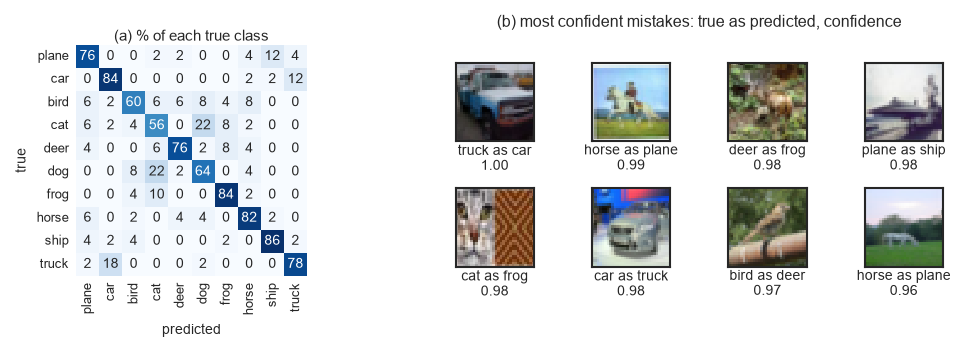

In [28]:
precision, recall, f1, _ = precision_recall_fscore_support(test_y, test_pred)
print(pd.DataFrame({"precision": precision, "recall": recall, "F1": f1}, index=classes).round(2).to_string())
confusion = pd.DataFrame(confusion_matrix(test_y, test_pred, normalize="true"), index=classes, columns=classes)
test_confusions = confusion.where(~np.eye(len(classes), dtype=bool)).stack().sort_values(ascending=False)
print("largest confusions:", test_confusions.head(6).round(2).to_dict())

def same_cluster_chance(a, b):
    counts = cluster_tables["embeddings"]
    return (counts[a] * counts[b]).sum() / (counts[a].sum() * counts[b].sum())

# pairs named in A2 and B3 before testing
pairs = [("cat", "dog"), ("airplane", "ship"), ("automobile", "truck"), ("deer", "horse")]
thread = pd.DataFrame({"A2 pixel lift": [mutual_lift[f"{a} and {b}"] for a, b in pairs],
                       "B3 same cluster": [same_cluster_chance(a, b) for a, b in pairs],
                       "C4 a as b": [confusion.loc[a, b] for a, b in pairs],
                       "C4 b as a": [confusion.loc[b, a] for a, b in pairs]},
                      index=[f"{a} and {b}" for a, b in pairs])
print(thread.round(3).to_string())
other_pairs = [(a, b) for i, a in enumerate(classes) for b in classes[i + 1:]]
print(f"average over all 45 class pairs: B3 same cluster {np.mean([same_cluster_chance(a, b) for a, b in other_pairs]):.3f}, "
      f"C4 confusion {test_confusions.mean():.3f}")

wrong = np.flatnonzero(test_pred != test_y.numpy())
shown = wrong[np.argsort(-test_prob[wrong].max(1).values.numpy())[:8]]
fig = plt.figure(figsize=(TEXT_WIDTH, 2.0))
matrix_fig, mistake_fig = fig.subfigures(1, 2, width_ratios=[1, 1.15])
ax = matrix_fig.subplots()
sns.heatmap(confusion * 100, ax=ax, cmap="Blues", annot=True, fmt=".0f", cbar=False, square=True,
            xticklabels=short_names, yticklabels=short_names)
ax.set(xlabel="predicted", ylabel="true", title="(a) % of each true class")
ax.tick_params(length=0)
mistake_axes = mistake_fig.subplots(2, 4, gridspec_kw={"wspace": 0.15, "hspace": 0.6})
mistake_fig.subplots_adjust(top=0.82, bottom=0.14, left=0.02, right=0.98)
for ax, i in zip(mistake_axes.flat, shown):
    ax.imshow(test_images[test_idx[i]])
    ax.set(xticks=[], yticks=[])
    ax.set_xlabel(f"{short_names[test_y[i]]} as {short_names[test_pred[i]]}\n{test_prob[i].max():.2f}", labelpad=1)
mistake_fig.suptitle("(b) most confident mistakes: true as predicted, confidence")
fig.savefig("figures/c2_confusion.png")
plt.show()

most confused pair: cat as dog; correct image 46, wrong image 35


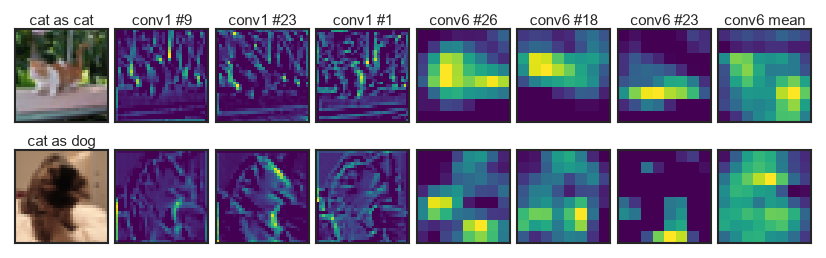

In [29]:
a, b = test_confusions.index[0]
true_a = np.flatnonzero(test_y.numpy() == classes.index(a))
correct_i = true_a[test_pred[true_a] == classes.index(a)][0]
wrong_i = true_a[test_pred[true_a] == classes.index(b)][0]
print(f"most confused pair: {a} as {b}; correct image {correct_i}, wrong image {wrong_i}")

relus = [m for m in final_model.features if isinstance(m, nn.ReLU)]
maps = {}

def keep_output(name):
    def hook(module, inputs, output):
        maps[name] = output.detach().cpu()
    return hook

hooks = [relus[0].register_forward_hook(keep_output("first")), relus[-1].register_forward_hook(keep_output("last"))]
# run the two images through once to fill the hooks
predict(final_model, test_x[[correct_i, wrong_i]])
for hook in hooks:
    hook.remove()
# rank channels on the correct image so both rows show the same ones
top = {name: maps[name][0].mean((1, 2)).argsort(descending=True)[:3] for name in maps}

fig, axes = plt.subplots(2, 8, figsize=(TEXT_WIDTH, 1.85), gridspec_kw={"wspace": 0.08, "hspace": 0.3})
for row, i in enumerate([correct_i, wrong_i]):
    axes[row, 0].imshow(test_images[test_idx[i]])
    axes[row, 0].set_title(f"{short_names[test_y[i]]} as {short_names[test_pred[i]]}")
    for j, ch in enumerate(top["first"]):
        axes[row, 1 + j].imshow(maps["first"][row, ch], cmap="viridis")
    for j, ch in enumerate(top["last"]):
        axes[row, 4 + j].imshow(maps["last"][row, ch], cmap="viridis")
    axes[row, 7].imshow(maps["last"][row].mean(0), cmap="viridis")
for j, ch in enumerate(top["first"]):
    axes[0, 1 + j].set_title(f"conv1 #{ch.item()}")
for j, ch in enumerate(top["last"]):
    axes[0, 4 + j].set_title(f"conv6 #{ch.item()}")
axes[0, 7].set_title("conv6 mean")
for ax in axes.flat:
    ax.set(xticks=[], yticks=[])
fig.savefig("figures/c4_feature_maps.png")
plt.show()